# 1. Objective

The objective of this notebook is to develop and evaluate machine learning models to predict the probability of credit card default in the following month.

Two classification models will be developed:

- **Logistic Regression:** An interpretable baseline model.
- **XGBoost:** A more flexible model capable of capturing nonlinear relationships and feature interactions.

Model performance will be compared using appropriate classification metrics, including ROC-AUC, PR-AUC, precision, and recall.

Beyond predictive performance, the analysis will consider model interpretability and probability calibration, with the aim of identifying a reliable model suitable for credit risk assessment.

The test dataset will remain untouched during model development and selection to ensure an unbiased final evaluation.


# 2. Data Loading and Preparation

In [1]:
# Import necessary libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    RocCurveDisplay,
    PrecisionRecallDisplay
)

In [2]:
# Load the dataset
data_path = '/Users/syryoo/Projects/risklab-credit-risk/data/raw/UCI_Credit_Card.csv'
df = pd.read_csv(data_path)

In [3]:
# Display the first few rows of the dataset
df.head()

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default.payment.next.month
0,1,20000.0,2,2,1,24,2,2,-1,-1,...,0.0,0.0,0.0,0.0,689.0,0.0,0.0,0.0,0.0,1
1,2,120000.0,2,2,2,26,-1,2,0,0,...,3272.0,3455.0,3261.0,0.0,1000.0,1000.0,1000.0,0.0,2000.0,1
2,3,90000.0,2,2,2,34,0,0,0,0,...,14331.0,14948.0,15549.0,1518.0,1500.0,1000.0,1000.0,1000.0,5000.0,0
3,4,50000.0,2,2,1,37,0,0,0,0,...,28314.0,28959.0,29547.0,2000.0,2019.0,1200.0,1100.0,1069.0,1000.0,0
4,5,50000.0,1,2,1,57,-1,0,-1,0,...,20940.0,19146.0,19131.0,2000.0,36681.0,10000.0,9000.0,689.0,679.0,0


In [4]:
# Drop the 'ID' column as it is not needed for modeling
df.drop(columns=['ID'], inplace=True)

In [5]:
# Split the dataset into features and target variable
X = df.drop(columns=['default.payment.next.month'])
y = df['default.payment.next.month']

# 3. Train/validation/test split

In [6]:
# Before spliting the dataset, preprocess EDUCATION variable
X.loc[X['EDUCATION'].isin([4, 5, 6]), 'EDUCATION'] = 0

In [7]:
# Split the dataset using a fixed stratified 70-15-15 ratio for training, validation, and testing. Also, set a random seed for reproducibility.
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp)

In [8]:
# Check the shapes of the resulting datasets
print(f'Training set shape: {X_train.shape}, {y_train.shape}')
print(f'Validation set shape: {X_val.shape}, {y_val.shape}')
print(f'Test set shape: {X_test.shape}, {y_test.shape}')

Training set shape: (21000, 23), (21000,)
Validation set shape: (4500, 23), (4500,)
Test set shape: (4500, 23), (4500,)


The dataset has been split into three parts: training, validation, and test sets. The training set will be used to fit models and preprocessing transformations. The validation set will be used to compare models and make modeling decisions. The test set will remain untouched until the final evaluation of the model's performance.

# 4. Preprocessing

Before proceeding with model training, some features may require preprocessing, such as scaling or encoding categorical variables. Let's check the data types of the features to identify any necessary preprocessing steps.

In [9]:
# Check the data types of the features to identify any necessary preprocessing steps
X_train.dtypes

LIMIT_BAL    float64
SEX            int64
EDUCATION      int64
MARRIAGE       int64
AGE            int64
PAY_0          int64
PAY_2          int64
PAY_3          int64
PAY_4          int64
PAY_5          int64
PAY_6          int64
BILL_AMT1    float64
BILL_AMT2    float64
BILL_AMT3    float64
BILL_AMT4    float64
BILL_AMT5    float64
BILL_AMT6    float64
PAY_AMT1     float64
PAY_AMT2     float64
PAY_AMT3     float64
PAY_AMT4     float64
PAY_AMT5     float64
PAY_AMT6     float64
dtype: object

All the features are numerical, but some of them are categorical in nature (e.g., `SEX`, `EDUCATION`, `MARRIAGE`, `PAY_0`, `PAY_2`, `PAY_3`, `PAY_4`, `PAY_5`, `PAY_6`). We will need to convert these features into categorical data types for proper handling during modeling.

Then, the numerical features in the dataset are `LIMIT_BAL`, `AGE`, `BILL_AMT1` to `BILL_AMT6`, and `PAY_AMT1` to `PAY_AMT6`. The categorical features are `SEX`, `EDUCATION`, `MARRIAGE`, and `PAY_0` to `PAY_6`.

For the categorical features, we will use one-hot encoding to convert them into a format suitable for modeling. On the other hand, for the numerical features, we will apply standard scaling to ensure that they have a mean of 0 and a standard deviation of 1. Although we observed that the numerical features were right-skewed, we will not apply any transformations to them at this stage just to keep the preprocessing simple. However, we will keep in mind that we may need to revisit this decision later if we find that the skewness of the numerical features is affecting the performance of our models.

However, for the XGBoost model, we won't apply  standard scaling to the numerical features, as XGBoost is not sensitive to the scale of the features. However, we will still apply one-hot encoding to the categorical features to ensure that they are in a suitable format for modeling.

4.1 Numerical Feature Diagnostics

Document:
1. Distribution characteristics.
2. Skewness.
3. Potential outliers.
4. Decisions regarding transformations or scaling.

In [10]:
# Define the numerical and categorical features
numerical_features = ['LIMIT_BAL', 'AGE', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6']
categorical_features = ['SEX', 'EDUCATION', 'MARRIAGE', 'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6']

In [11]:
# Set a preprocessing pipeline for the logistic regression model
numerical_transformer = StandardScaler()

categorical_transformer = OneHotEncoder(handle_unknown='ignore')

lr_preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

In [12]:
# Set a preprocessing pipeline for the XGBoost model
xgboost_preprocessor = ColumnTransformer(
    transformers=[
        ("cat", categorical_transformer, categorical_features)
    ],
    remainder='passthrough'  # Keep the numerical features as they are
)

# 5. Baseline Model

As a baseline model, we will use logistic regression. Logistic regression is a simple and interpretable model that can provide a good starting point for our credit risk prediction task. We will train the logistic regression model using the preprocessed training data and evaluate its performance on the validation set.

In [13]:
# Define the logistic regression pipeline
lr_pipeline = Pipeline(steps=[
    ("preprocessor", lr_preprocessor),
    ("classifier", LogisticRegression())
])

In [14]:
# Train the logistic regression model
lr_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](23,)","['LIMIT_BAL','SEX','EDUCATION',...,'PAY_AMT4','PAY_AMT5','PAY_AMT6']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,23
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, al

# 6. Advanced Model

We also train the XGBoost model using the preprocessor defined above. XGBoost is a powerful gradient boosting algorithm that can handle both numerical and categorical features effectively. After training, we evaluate the performance of both models on the validation set to compare their accuracy and other relevant metrics.

In [15]:
# Define the XGBoost pipeline
xgboost_pipeline = Pipeline(steps=[
    ("preprocessor", xgboost_preprocessor),
    ("classifier", XGBClassifier())
])

In [16]:
# Train the XGBoost model
xgboost_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](23,)","['LIMIT_BAL','SEX','EDUCATION',...,'PAY_AMT4','PAY_AMT5','PAY_AMT6']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,23
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining co

# 7. Model Evaluation

Different metrics are used to evaluate the performance of the models, including accuracy, precision, recall, F1-score, and ROC-AUC. These metrics provide insights into how well the models are performing in predicting the target variable.

In [17]:
# Predict class labels using the logistic regression model
y_pred_lr = lr_pipeline.predict(X_val)

# Predict default probabilities
y_proba_lr = lr_pipeline.predict_proba(X_val)[:, 1]

# Predict class labels using the XGBoost model
y_pred_xgboost = xgboost_pipeline.predict(X_val)

# Predict default probabilities using the XGBoost model
y_proba_xgboost = xgboost_pipeline.predict_proba(X_val)[:, 1]

In [18]:
# Evaluate the logistic regression model
metrics_lr = {
    "Accuracy": accuracy_score(y_val, y_pred_lr),
    "Precision": precision_score(y_val, y_pred_lr),
    "Recall": recall_score(y_val, y_pred_lr),
    "F1-score": f1_score(y_val, y_pred_lr),
    "ROC-AUC": roc_auc_score(y_val, y_proba_lr),
    "PR-AUC": average_precision_score(y_val, y_proba_lr)
}

# Evaluate the XGBoost model
metrics_xgboost = {
    "Accuracy": accuracy_score(y_val, y_pred_xgboost),
    "Precision": precision_score(y_val, y_pred_xgboost),
    "Recall": recall_score(y_val, y_pred_xgboost),
    "F1-score": f1_score(y_val, y_pred_xgboost),
    "ROC-AUC": roc_auc_score(y_val, y_proba_xgboost),
    "PR-AUC": average_precision_score(y_val, y_proba_xgboost)
}

print("Logistic Regression Metrics:")
print(pd.Series(metrics_lr).round(4))

print("\nXGBoost Metrics:")
print(pd.Series(metrics_xgboost).round(4))

Logistic Regression Metrics:
Accuracy     0.8189
Precision    0.6751
Recall       0.3487
F1-score     0.4599
ROC-AUC      0.7649
PR-AUC       0.5247
dtype: float64

XGBoost Metrics:
Accuracy     0.8100
Precision    0.6232
Recall       0.3558
F1-score     0.4530
ROC-AUC      0.7588
PR-AUC       0.5207
dtype: float64


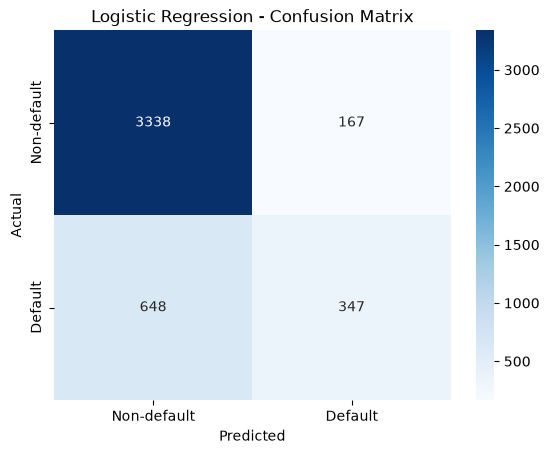

In [19]:
# Visualize the confusion matrix for the logistic regression model
cm = confusion_matrix(y_val, y_pred_lr)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Non-default", "Default"],
    yticklabels=["Non-default", "Default"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Logistic Regression - Confusion Matrix")
plt.show()

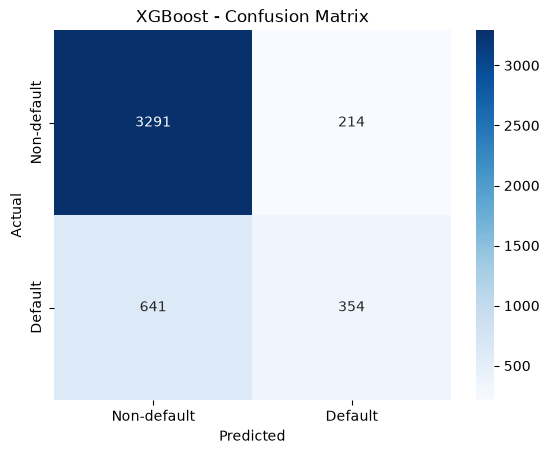

In [20]:
# Visualize the confusion matrix for the XGBoost model
cm = confusion_matrix(y_val, y_pred_xgboost)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Non-default", "Default"],
    yticklabels=["Non-default", "Default"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("XGBoost - Confusion Matrix")
plt.show()

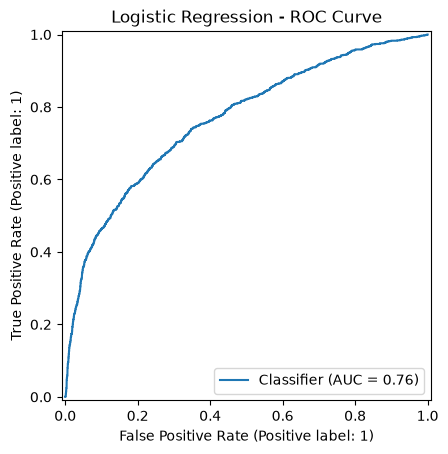

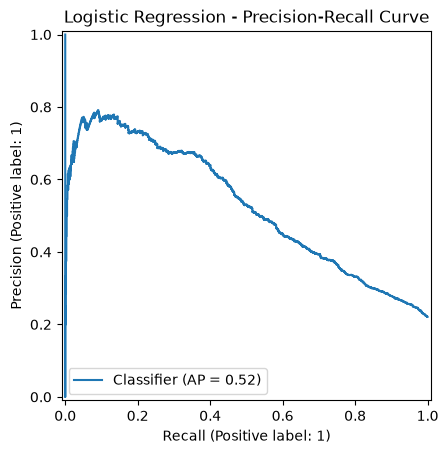

In [21]:
# Visualize the ROC and Precision-Recall curves for the logistic regression model
RocCurveDisplay.from_predictions(y_val, y_proba_lr)
plt.title("Logistic Regression - ROC Curve")
plt.show()

PrecisionRecallDisplay.from_predictions(y_val, y_proba_lr)
plt.title("Logistic Regression - Precision-Recall Curve")
plt.show()

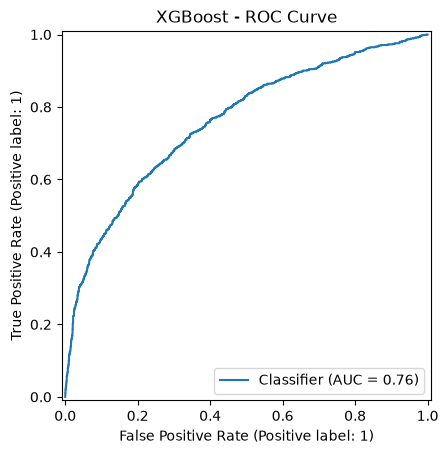

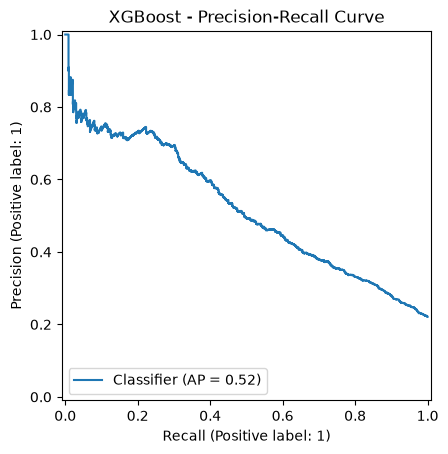

In [22]:
# Visualize the ROC and Precision-Recall curves for the XGBoost model
RocCurveDisplay.from_predictions(y_val, y_proba_xgboost)
plt.title("XGBoost - ROC Curve")
plt.show()

PrecisionRecallDisplay.from_predictions(y_val, y_proba_xgboost)
plt.title("XGBoost - Precision-Recall Curve")
plt.show()

In [23]:
# Display the classification report for the both models
print("Logistic Regression Classification Report:")
print(classification_report(y_val, y_pred_lr))

print("\nXGBoost Classification Report:")
print(classification_report(y_val, y_pred_xgboost))

Logistic Regression Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.95      0.89      3505
           1       0.68      0.35      0.46       995

    accuracy                           0.82      4500
   macro avg       0.76      0.65      0.68      4500
weighted avg       0.80      0.82      0.80      4500


XGBoost Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.94      0.89      3505
           1       0.62      0.36      0.45       995

    accuracy                           0.81      4500
   macro avg       0.73      0.65      0.67      4500
weighted avg       0.79      0.81      0.79      4500



The logistic regression outperforms the XGBoost model in terms of all evaluation metrics, except recall meaning that the XGBoost model was a bit better at classifying correctly the defaults next month. 

# 8. Initial Feature Importance

## 8.1. Logistic Regression

In [24]:
# Examine the coefficients of the logistic regression model to understand the impact of each feature on the prediction
coefficients = lr_pipeline.named_steps['classifier'].coef_[0]
coeff_df = pd.DataFrame({
    'Feature': numerical_features + list(lr_pipeline.named_steps['preprocessor'].transformers_[1][1].get_feature_names_out(categorical_features)),
    'Coefficient': coefficients,
    'Odds Ratio': np.exp(coefficients),
    'Direction': ['Positive' if coef > 0 else 'Negative' for coef in coefficients]
}).sort_values(by='Coefficient', ascending=False)

In [25]:
coeff_df.head(10)

,Feature,Coefficient,Odds Ratio,Direction
29,PAY_0_3,1.036171,2.818404,Positive
28,PAY_0_2,0.999805,2.717753,Positive
42,PAY_2_5,0.565473,1.760281,Positive
30,PAY_0_4,0.557049,1.745513,Positive
83,PAY_6_4,0.492537,1.636463,Positive
54,PAY_3_6,0.464774,1.591654,Positive
23,MARRIAGE_3,0.382602,1.466095,Positive
33,PAY_0_7,0.364482,1.439768,Positive
43,PAY_2_6,0.329016,1.389601,Positive
82,PAY_6_3,0.289102,1.335227,Positive


In [26]:
coeff_df.tail(10)

,Feature,Coefficient,Odds Ratio,Direction
79,PAY_6_-1,-0.363015,0.695576,Negative
80,PAY_6_0,-0.489614,0.612863,Negative
25,PAY_0_-1,-0.541165,0.582070,Negative
73,PAY_5_4,-0.630032,0.532575,Negative
64,PAY_4_5,-0.650544,0.521762,Negative
41,PAY_2_4,-0.659100,0.517317,Negative
16,EDUCATION_0,-0.818814,0.440954,Negative
20,MARRIAGE_0,-0.859992,0.423166,Negative
24,PAY_0_-2,-1.021587,0.360023,Negative
26,PAY_0_0,-1.333113,0.263655,Negative


The variable `PAY_0_3` has the largest coefficient value of 1.04, meaning that clients who were 3 months delinquent in September 2025 have roughly 2.8 times the odds of defaulting next month compared to clients who were not, holding all other variables in the model constant.

To understand how much each feature contributes to the predictive performance, permutation importance is also computed. It measures how much the model's predictive performance deteriorates when the values of one feature are randomly shuffled. Then, if a feature is important for making predictions, disrupting its values should make the model perform worse.

In [27]:
# Compute feature importance
from sklearn.inspection import permutation_importance
perm_importance = permutation_importance(lr_pipeline, X_val, y_val, scoring="roc_auc", n_repeats=10, random_state=42, n_jobs=-1)

perm_importance_df = pd.DataFrame({
    "feature": X_val.columns,
    "importance_mean": perm_importance.importances_mean,
    "importance_std": perm_importance.importances_std
}).sort_values(
    "importance_mean",
    ascending=False
)

perm_importance_df

,feature,importance_mean,importance_std
5,PAY_0,0.129446,0.004962
0,LIMIT_BAL,0.026935,0.002583
10,PAY_6,0.011444,0.003452
18,PAY_AMT2,0.007701,0.001566
13,BILL_AMT3,0.005954,0.001768
7,PAY_3,0.005696,0.002472
8,PAY_4,0.005150,0.001563
17,PAY_AMT1,0.004126,0.001003
6,PAY_2,0.002487,0.001378
9,PAY_5,0.001959,0.001878


Based on the result, `PAY_0` seems to be the most important predictor of the model. The average change in the ROC-AUC for this feature is 0.13, meaning that disrupting its values leads to a reduction of the ROC-AUC metric by 0.13.

On the other hand, `PAY_AMT6` has a negative average importance, which indicates that shuffling this feature actually improves model performance. This may suggest that the feature might be adding noise or contributing to overfitting. The model would have learned patterns from this variable during training that wouldn't generalize well to unseen customers and when the patterns are disrupted by shuffling the values, the model now makes slightly better predictions.

The variable `LIMIT_BAL` has the second largest contribution to the model performance while it does not have a large coefficient.

# 8.2 XGBoost

In [28]:
# Examine the feature importances of the XGBoost model to understand the impact of each feature on the prediction
feature_importances = xgboost_pipeline.named_steps['classifier'].feature_importances_
feature_names = numerical_features + list(xgboost_pipeline.named_steps['preprocessor'].transformers_[0][1].get_feature_names_out(categorical_features))
importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': feature_importances
}).sort_values(by='Importance', ascending=False)  
importance_df

,Feature,Importance
14,SEX_1,0.267506
25,PAY_0_-1,0.164955
36,PAY_2_-1,0.062326
26,PAY_0_0,0.054666
47,PAY_3_-1,0.034409
...,...,...
29,PAY_0_3,0.000000
46,PAY_3_-2,0.000000
1,AGE,0.000000
30,PAY_0_4,0.000000


In [29]:
importance_df['Importance'].sum()

np.float32(1.0)

The feature importance represent the average gain (improvement in the objective function) from splits involving each feature. The values are normalized in the the sum is equal to 1. Features that are never used in a split have an importance of 0.

Based on the resuls, the gender of the clients is the feature that improves the most in the objective function of the model. This observation is not aligned with what we observed in the logistic regression model. 

There are quite a lot of variables that are never used in a split, such as, the age of the clients.